KdV ICL MULTI-FIDELITY DATASET GENERATOR
PDE       : u_t - eps*u_xxx + (u^2/2)_x = 0
domain    : [0,2.0) periodic
time      : [0,2.0]
Delta     : 0.2
input t   : [0.000000, 1.800000]
target t  : [0.200000, 2.000000]
eps       : U[0.01,0.02]
c1        : U[2.0,3.0]
x1        : 1.0
N operators: 200
N samples/operator: 100
split     : 140 train / 60 held-out operators
Nc/Nf/Nr  : 24/256/100
dt        : 0.0005
dealias   : True

Operator parameter summary:
eps actual range = [0.010035, 0.019969]
c1  actual range = [2.003582, 2.999133]
train op indices (0-based): [  0   1   3   4   5   6   7   8   9  10  12  14  16  17  20  21  22  23
  24  25  26  28  29  30  31  32  33  34  35  36  38  43  44  46  47  48
  49  50  52  54  55  56  57  59  60  62  63  64  65  67  70  71  72  73
  74  76  78  79  80  82  84  85  87  88  91  93  94  95  96 100 101 102
 103 104 105 106 107 109 112 113 116 117 118 121 124 125 127 128 129 130
 131 133 134 135 136 138 140 141 142 143 144 145 146 147 150 151 152 153

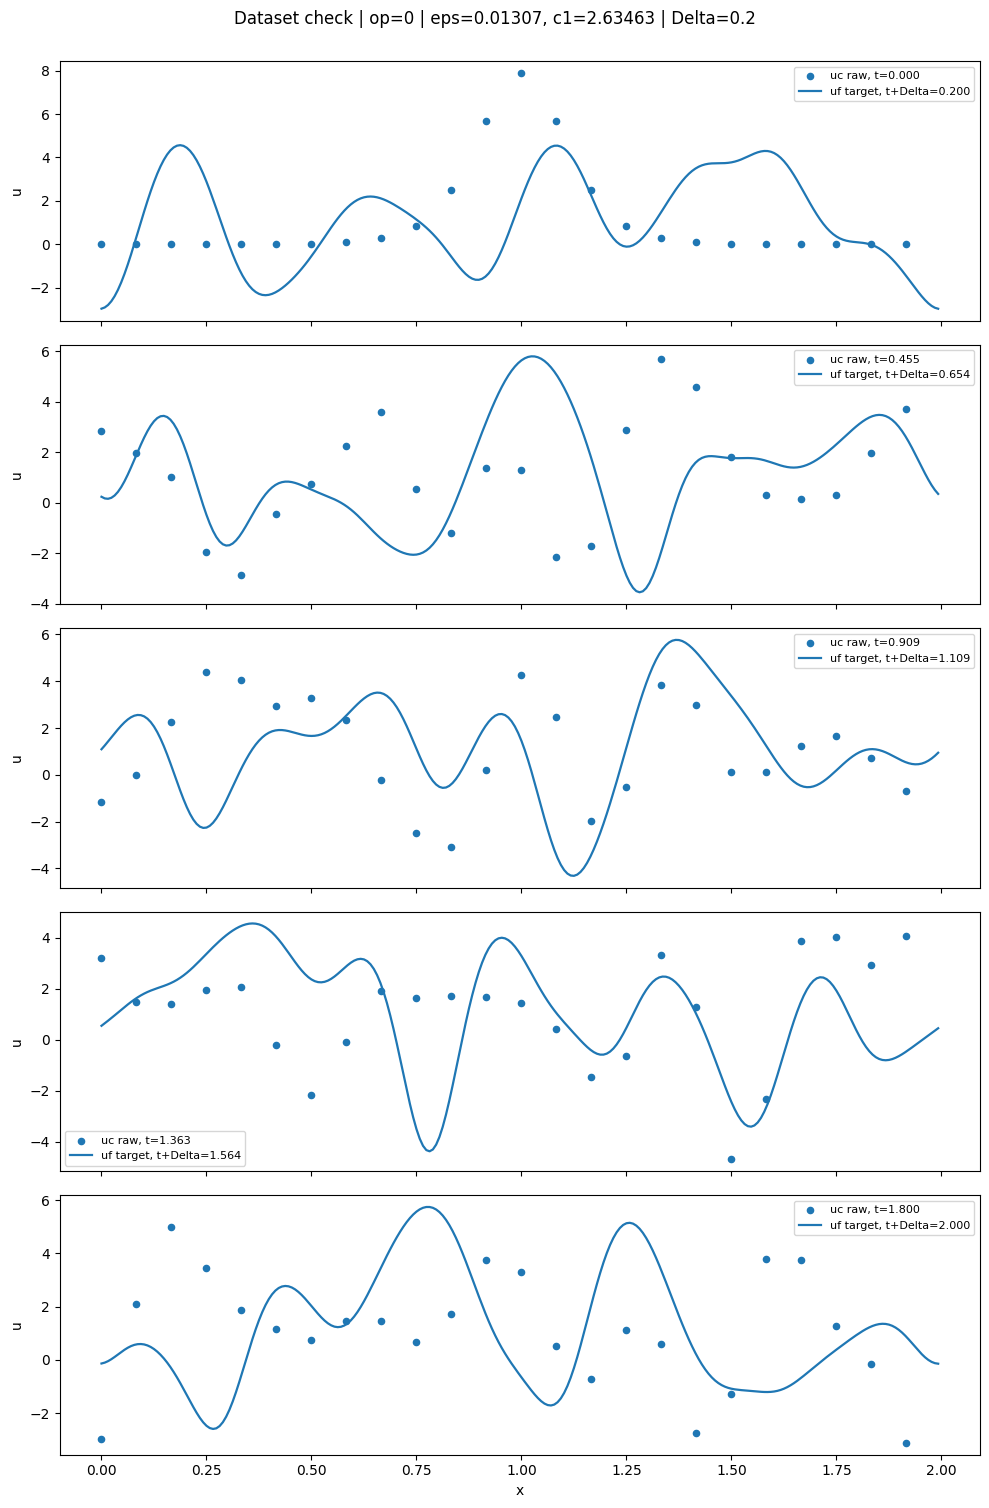

Check plot: /kaggle/working/kdv_icl_dataset_delta020/kdv_icl_eps001_002_c1_2_3_Nop200_Ns100_Nc24_Nf256_Nr100_delta020_check.png

DONE
Main training pair:
  uc[i,j,:] = coarse solution at t_in[j]
  uf[i,j,:] = fine solution at t_out[j] = t_in[j] + 0.2
Operator:
  i = (eps_i, c1_i)
Sample input:
  xi = t
Use train_op_idx/test_op_idx for unseen-operator evaluation.


In [1]:
# ============================================================
# KdV ICL MULTI-FIDELITY DATASET GENERATOR
# ============================================================
#
# Final candidate setting
# -----------------------
# PDE:
#   u_t - eps*u_xxx + (u^2/2)_x = 0
#
# Domain / BC:
#   x in [0,2), periodic BC
#
# Time:
#   t in [0,2]
#
# Initial condition:
#   u(x,0) = 3*c1*sech^2( 0.5*sqrt(c1/eps)*(x-x1) )
#   x1 = 1
#
# Operator parameters:
#   eps ~ U[0.01,0.02]
#   c1  ~ U[2,3]
#
# Multi-fidelity:
#   coarse Nx = 24
#   fine   Nx = 256
#
# Time-shifted MF pair:
#   input  = u_c(x,t)
#   target = u_f(x,t + Delta)
#   Delta  = 0.2
#
# ICL interpretation:
#   operator i = (eps_i, c1_i)
#   sample input xi = t
#
# Default dataset:
#   200 operators
#   100 time samples/operator
#   140 train operators / 60 held-out operators
#
# The code saves:
#   uc_raw        : coarse at t
#   uf_raw        : fine at t+Delta      <-- main target
#   uf_same_raw   : fine at t            <-- diagnostic only
#   uc_common     : uc_raw mapped to Nr=100
#   uf_common     : uf_raw mapped to Nr=100
#   uf_same_common: uf_same_raw mapped to Nr=100
#   eps, c1, t_in, t_out, grids, splits, metadata
#
# Internal solver:
#   periodic Fourier pseudo-spectral + ETDRK4
#   2/3 de-aliasing
#
# Saves both .npz and .mat.
# ============================================================

import os
import time
import json
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import savemat

# ------------------------------------------------------------
# 0. USER SETTINGS
# ------------------------------------------------------------
OUT_DIR = "/kaggle/working/kdv_icl_dataset_delta020"
os.makedirs(OUT_DIR, exist_ok=True)

SEED = 913

# PDE/domain
L = 2.0
T_FINAL = 2.0
BETA = 1.0
X1 = 1.0

# Operator box
EPS_MIN, EPS_MAX = 0.01, 0.02
C1_MIN, C1_MAX = 2.0, 3.0

# Dataset size
N_OP = 200
N_SAMPLE = 100

# Operator-level split
N_TRAIN_OP = 140
N_TEST_OP = N_OP - N_TRAIN_OP

# Multi-fidelity spatial resolutions
NC = 24
NF = 256

# Common model grid
NR = 100

# Time integration
DT = 5.0e-4
DELTA = 0.2

# Solver
USE_DEALIAS = True

# Save type
SAVE_FLOAT_DTYPE = np.float32

# Optional quick test.
# If True, only generate 4 operators x 10 time samples.
QUICK_TEST = False

# Checkpoint after this many operators
CHECKPOINT_EVERY = 10

# ------------------------------------------------------------
# 1. BASIC CHECKS / EFFECTIVE SETTINGS
# ------------------------------------------------------------
if QUICK_TEST:
    N_OP_EFF = 4
    N_SAMPLE_EFF = 10
    N_TRAIN_EFF = 3
else:
    N_OP_EFF = N_OP
    N_SAMPLE_EFF = N_SAMPLE
    N_TRAIN_EFF = N_TRAIN_OP

N_TEST_EFF = N_OP_EFF - N_TRAIN_EFF

nsteps = int(round(T_FINAL / DT))
delta_steps = int(round(DELTA / DT))

if not np.isclose(delta_steps * DT, DELTA):
    raise ValueError(
        f"DELTA={DELTA} is not an integer multiple of DT={DT}."
    )

max_input_step = nsteps - delta_steps

if max_input_step < 0:
    raise ValueError("DELTA must be smaller than or equal to T_FINAL.")

# Exact solver time indices for the N_SAMPLE inputs.
# We intentionally choose exact time steps so no temporal interpolation
# is introduced into the dataset.
input_steps = np.rint(
    np.linspace(0, max_input_step, N_SAMPLE_EFF)
).astype(int)

if len(np.unique(input_steps)) != N_SAMPLE_EFF:
    raise RuntimeError(
        "N_SAMPLE is too large relative to available solver steps."
    )

output_steps = input_steps + delta_steps

t_in = input_steps * DT
t_out = output_steps * DT

needed_steps = np.unique(
    np.concatenate([input_steps, output_steps])
)

print("="*120)
print("KdV ICL MULTI-FIDELITY DATASET GENERATOR")
print("="*120)
print("PDE       : u_t - eps*u_xxx + (u^2/2)_x = 0")
print(f"domain    : [0,{L}) periodic")
print(f"time      : [0,{T_FINAL}]")
print(f"Delta     : {DELTA}")
print(f"input t   : [{t_in.min():.6f}, {t_in.max():.6f}]")
print(f"target t  : [{t_out.min():.6f}, {t_out.max():.6f}]")
print(f"eps       : U[{EPS_MIN},{EPS_MAX}]")
print(f"c1        : U[{C1_MIN},{C1_MAX}]")
print(f"x1        : {X1}")
print(f"N operators: {N_OP_EFF}")
print(f"N samples/operator: {N_SAMPLE_EFF}")
print(f"split     : {N_TRAIN_EFF} train / {N_TEST_EFF} held-out operators")
print(f"Nc/Nf/Nr  : {NC}/{NF}/{NR}")
print(f"dt        : {DT}")
print(f"dealias   : {USE_DEALIAS}")
print("="*120)


# ------------------------------------------------------------
# 2. HELPERS
# ------------------------------------------------------------
def sech(z):
    return 1.0 / np.cosh(z)


def initial_condition(x, c1, eps, x1=X1):
    k1 = 0.5 * np.sqrt(c1 / eps)
    return 3.0 * c1 * sech(k1 * (x - x1))**2


def fourier_wavenumbers(N, L):
    return 2.0 * np.pi * np.fft.fftfreq(N, d=L/N)


def dealias_mask(N):
    mode = np.fft.fftfreq(N) * N
    return (np.abs(mode) <= N/3.0).astype(float)


def nonlinear_hat(u, k, beta, mask=None):
    # -(u^2/2)_x
    nh = -0.5 * beta * (1j*k) * np.fft.fft(u*u)
    if mask is not None:
        nh = nh * mask
    return nh


def solve_kdv_selected_steps(
    u0,
    eps,
    beta,
    L,
    T,
    dt,
    selected_steps,
    use_dealias=True,
):
    """
    Periodic Fourier pseudo-spectral ETDRK4 solver.

    Solves:
        u_t - eps*u_xxx + beta*(u^2/2)_x = 0

    Returns only the requested exact time-step snapshots.
    """
    N = len(u0)
    k = fourier_wavenumbers(N, L)
    mask = dealias_mask(N) if use_dealias else None

    # u_t = eps*u_xxx - beta*(u^2/2)_x
    Lhat = eps * (1j*k)**3

    E = np.exp(dt * Lhat)
    E2 = np.exp(dt * Lhat / 2.0)

    # Kassam-Trefethen ETDRK4 contour coefficients
    M = 64
    r = np.exp(
        1j*np.pi*(np.arange(1, M+1)-0.5)/M
    )
    LR = dt*Lhat[:, None] + r[None, :]

    Q = dt*np.mean(
        (np.exp(LR/2.0)-1.0)/LR,
        axis=1
    )
    f1 = dt*np.mean(
        (-4.0-LR + np.exp(LR)*(4.0-3.0*LR+LR**2))
        / (LR**3),
        axis=1
    )
    f2 = dt*np.mean(
        (2.0+LR + np.exp(LR)*(-2.0+LR))
        / (LR**3),
        axis=1
    )
    f3 = dt*np.mean(
        (-4.0-3.0*LR-LR**2 + np.exp(LR)*(4.0-LR))
        / (LR**3),
        axis=1
    )

    uhat = np.fft.fft(u0)

    selected_steps = np.asarray(selected_steps, dtype=int)
    selected_set = set(selected_steps.tolist())
    selected_map = {}

    if 0 in selected_set:
        selected_map[0] = np.real(np.fft.ifft(uhat)).copy()

    nsteps_local = int(round(T/dt))

    for n in range(1, nsteps_local+1):
        u = np.real(np.fft.ifft(uhat))
        Nv = nonlinear_hat(u, k, beta, mask)

        a_hat = E2*uhat + Q*Nv
        a = np.real(np.fft.ifft(a_hat))
        Na = nonlinear_hat(a, k, beta, mask)

        b_hat = E2*uhat + Q*Na
        b = np.real(np.fft.ifft(b_hat))
        Nb = nonlinear_hat(b, k, beta, mask)

        c_hat = E2*a_hat + Q*(2.0*Nb-Nv)
        c = np.real(np.fft.ifft(c_hat))
        Nc_hat = nonlinear_hat(c, k, beta, mask)

        uhat = (
            E*uhat
            + f1*Nv
            + 2.0*f2*(Na+Nb)
            + f3*Nc_hat
        )

        if n in selected_set:
            selected_map[n] = np.real(
                np.fft.ifft(uhat)
            ).copy()

        if not np.all(np.isfinite(uhat)):
            raise FloatingPointError(
                f"Non-finite solution at step={n}, eps={eps}, N={N}"
            )

    missing = [
        s for s in selected_steps
        if s not in selected_map
    ]
    if missing:
        raise RuntimeError(
            f"Missing requested steps: {missing[:10]}"
        )

    U = np.stack(
        [selected_map[int(s)] for s in selected_steps],
        axis=0
    )

    return U


def periodic_linear_interp(x_src, u_src, x_dst, L):
    return np.interp(
        x_dst,
        x_src,
        u_src,
        period=L
    )


def interp_trajectory(x_src, U_src, x_dst, L):
    return np.asarray([
        periodic_linear_interp(
            x_src, u, x_dst, L
        )
        for u in U_src
    ])


def rel_l2(pred, ref):
    pred = np.asarray(pred)
    ref = np.asarray(ref)
    return float(
        np.linalg.norm(pred-ref)
        / max(np.linalg.norm(ref), 1e-300)
    )


def lhs_box(n, lows, highs, seed):
    """
    Simple Latin-hypercube sampling without scipy.stats.qmc dependency.
    """
    rng = np.random.default_rng(seed)
    d = len(lows)
    X = np.empty((n, d), dtype=np.float64)

    for j in range(d):
        perm = rng.permutation(n)
        u = (perm + rng.random(n)) / n
        X[:, j] = lows[j] + u*(highs[j]-lows[j])

    # Randomize row ordering after LHS construction
    X = X[rng.permutation(n)]
    return X


# ------------------------------------------------------------
# 3. GRIDS AND OPERATORS
# ------------------------------------------------------------
x_c = np.linspace(
    0.0, L, NC, endpoint=False
)
x_f = np.linspace(
    0.0, L, NF, endpoint=False
)
x_r = np.linspace(
    0.0, L, NR, endpoint=False
)

op_params = lhs_box(
    N_OP_EFF,
    lows=[EPS_MIN, C1_MIN],
    highs=[EPS_MAX, C1_MAX],
    seed=SEED,
)

eps_arr = op_params[:, 0]
c1_arr = op_params[:, 1]

# Reproducible operator split
rng_split = np.random.default_rng(SEED + 1000)
perm = rng_split.permutation(N_OP_EFF)

train_op_idx = np.sort(
    perm[:N_TRAIN_EFF]
)
test_op_idx = np.sort(
    perm[N_TRAIN_EFF:]
)

print("\nOperator parameter summary:")
print(
    f"eps actual range = "
    f"[{eps_arr.min():.6f}, {eps_arr.max():.6f}]"
)
print(
    f"c1  actual range = "
    f"[{c1_arr.min():.6f}, {c1_arr.max():.6f}]"
)
print(
    "train op indices (0-based):",
    train_op_idx
)
print(
    "test op indices  (0-based):",
    test_op_idx
)


# ------------------------------------------------------------
# 4. PREALLOCATE DATASET ARRAYS
# ------------------------------------------------------------
uc_raw = np.empty(
    (N_OP_EFF, N_SAMPLE_EFF, NC),
    dtype=SAVE_FLOAT_DTYPE
)

uf_raw = np.empty(
    (N_OP_EFF, N_SAMPLE_EFF, NF),
    dtype=SAVE_FLOAT_DTYPE
)

# Same-time fine field for diagnostics / optional baselines
uf_same_raw = np.empty(
    (N_OP_EFF, N_SAMPLE_EFF, NF),
    dtype=SAVE_FLOAT_DTYPE
)

# Common-grid model representation
uc_common = np.empty(
    (N_OP_EFF, N_SAMPLE_EFF, NR),
    dtype=SAVE_FLOAT_DTYPE
)

uf_common = np.empty(
    (N_OP_EFF, N_SAMPLE_EFF, NR),
    dtype=SAVE_FLOAT_DTYPE
)

uf_same_common = np.empty(
    (N_OP_EFF, N_SAMPLE_EFF, NR),
    dtype=SAVE_FLOAT_DTYPE
)

# Per-operator diagnostic difficulty
same_time_relL2 = np.empty(
    N_OP_EFF,
    dtype=np.float64
)

shifted_relL2 = np.empty(
    N_OP_EFF,
    dtype=np.float64
)


# ------------------------------------------------------------
# 5. GENERATE DATASET
# ------------------------------------------------------------
print("\n" + "="*120)
print("GENERATING OPERATORS")
print("="*120)

start_all = time.time()

for i in range(N_OP_EFF):
    eps = float(eps_arr[i])
    c1 = float(c1_arr[i])

    tic = time.time()

    # Initial data at each fidelity
    u0_c = initial_condition(
        x_c, c1, eps, X1
    )
    u0_f = initial_condition(
        x_f, c1, eps, X1
    )

    # Solve only at required input/output times
    Uc_needed = solve_kdv_selected_steps(
        u0_c,
        eps,
        BETA,
        L,
        T_FINAL,
        DT,
        needed_steps,
        USE_DEALIAS,
    )

    Uf_needed = solve_kdv_selected_steps(
        u0_f,
        eps,
        BETA,
        L,
        T_FINAL,
        DT,
        needed_steps,
        USE_DEALIAS,
    )

    # Map requested solver step -> row in U*_needed
    step_to_row = {
        int(s): j
        for j, s in enumerate(needed_steps)
    }

    in_rows = np.asarray(
        [step_to_row[int(s)] for s in input_steps],
        dtype=int
    )

    out_rows = np.asarray(
        [step_to_row[int(s)] for s in output_steps],
        dtype=int
    )

    Uc_t = Uc_needed[in_rows]
    Uf_t = Uf_needed[in_rows]
    Uf_tplus = Uf_needed[out_rows]

    # Save raw spatial grids
    uc_raw[i] = Uc_t.astype(
        SAVE_FLOAT_DTYPE
    )
    uf_same_raw[i] = Uf_t.astype(
        SAVE_FLOAT_DTYPE
    )
    uf_raw[i] = Uf_tplus.astype(
        SAVE_FLOAT_DTYPE
    )

    # Common-grid representation
    Uc_r = interp_trajectory(
        x_c, Uc_t, x_r, L
    )
    Uf_same_r = interp_trajectory(
        x_f, Uf_t, x_r, L
    )
    Uf_shift_r = interp_trajectory(
        x_f, Uf_tplus, x_r, L
    )

    uc_common[i] = Uc_r.astype(
        SAVE_FLOAT_DTYPE
    )
    uf_same_common[i] = Uf_same_r.astype(
        SAVE_FLOAT_DTYPE
    )
    uf_common[i] = Uf_shift_r.astype(
        SAVE_FLOAT_DTYPE
    )

    # Diagnostic raw difficulty on common grid.
    # same_time: spatial fidelity gap only
    same_time_relL2[i] = rel_l2(
        Uc_r,
        Uf_same_r
    )

    # shifted: actual ICL mapping difficulty before learning
    shifted_relL2[i] = rel_l2(
        Uc_r,
        Uf_shift_r
    )

    elapsed = time.time() - tic

    print(
        f"[{i+1:03d}/{N_OP_EFF:03d}] "
        f"eps={eps:.6f}, c1={c1:.6f} | "
        f"same-time raw={100*same_time_relL2[i]:7.3f}% | "
        f"Delta={DELTA:g} raw={100*shifted_relL2[i]:7.3f}% | "
        f"{elapsed:.2f}s"
    )

    # Lightweight recovery checkpoint
    if (
        ((i+1) % CHECKPOINT_EVERY == 0)
        or (i == N_OP_EFF-1)
    ):
        ckpt_path = os.path.join(
            OUT_DIR,
            "generation_checkpoint.npz"
        )
        np.savez_compressed(
            ckpt_path,
            completed_operators=np.asarray([i+1]),
            eps=eps_arr[:i+1],
            c1=c1_arr[:i+1],
            uc_raw=uc_raw[:i+1],
            uf_raw=uf_raw[:i+1],
            uf_same_raw=uf_same_raw[:i+1],
            uc_common=uc_common[:i+1],
            uf_common=uf_common[:i+1],
            uf_same_common=uf_same_common[:i+1],
            same_time_relL2=same_time_relL2[:i+1],
            shifted_relL2=shifted_relL2[:i+1],
        )

total_minutes = (time.time()-start_all)/60.0

print("\n" + "="*120)
print("GENERATION COMPLETE")
print("="*120)
print(f"Total runtime: {total_minutes:.2f} min")


# ------------------------------------------------------------
# 6. FINAL SANITY CHECKS
# ------------------------------------------------------------
for name, arr in [
    ("uc_raw", uc_raw),
    ("uf_raw", uf_raw),
    ("uf_same_raw", uf_same_raw),
    ("uc_common", uc_common),
    ("uf_common", uf_common),
    ("uf_same_common", uf_same_common),
]:
    if not np.all(np.isfinite(arr)):
        raise FloatingPointError(
            f"{name} contains NaN/Inf."
        )

print("\nArray shapes:")
print("uc_raw        :", uc_raw.shape)
print("uf_raw        :", uf_raw.shape)
print("uf_same_raw   :", uf_same_raw.shape)
print("uc_common     :", uc_common.shape)
print("uf_common     :", uf_common.shape)
print("uf_same_common:", uf_same_common.shape)

print("\nRaw difficulty across operators:")
print(
    f"same-time mean  = "
    f"{100*np.mean(same_time_relL2):.6f}%"
)
print(
    f"same-time median= "
    f"{100*np.median(same_time_relL2):.6f}%"
)
print(
    f"same-time range = "
    f"[{100*np.min(same_time_relL2):.6f}%, "
    f"{100*np.max(same_time_relL2):.6f}%]"
)

print(
    f"\nDelta={DELTA:g} raw mean  = "
    f"{100*np.mean(shifted_relL2):.6f}%"
)
print(
    f"Delta={DELTA:g} raw median= "
    f"{100*np.median(shifted_relL2):.6f}%"
)
print(
    f"Delta={DELTA:g} raw range = "
    f"[{100*np.min(shifted_relL2):.6f}%, "
    f"{100*np.max(shifted_relL2):.6f}%]"
)


# ------------------------------------------------------------
# 7. SAVE FINAL DATASET
# ------------------------------------------------------------
dataset_name = (
    f"kdv_icl_eps001_002_c1_2_3_"
    f"Nop{N_OP_EFF}_Ns{N_SAMPLE_EFF}_"
    f"Nc{NC}_Nf{NF}_Nr{NR}_delta020"
)

npz_path = os.path.join(
    OUT_DIR,
    dataset_name + ".npz"
)

mat_path = os.path.join(
    OUT_DIR,
    dataset_name + ".mat"
)

metadata = {
    "pde":
        "u_t - eps*u_xxx + (u^2/2)_x = 0",
    "domain":
        [0.0, L],
    "periodic_bc":
        True,
    "T_FINAL":
        T_FINAL,
    "DT":
        DT,
    "DELTA":
        DELTA,
    "BETA":
        BETA,
    "X1":
        X1,
    "EPS_RANGE":
        [EPS_MIN, EPS_MAX],
    "C1_RANGE":
        [C1_MIN, C1_MAX],
    "N_OP":
        N_OP_EFF,
    "N_SAMPLE":
        N_SAMPLE_EFF,
    "NC":
        NC,
    "NF":
        NF,
    "NR":
        NR,
    "N_TRAIN_OP":
        N_TRAIN_EFF,
    "N_TEST_OP":
        N_TEST_EFF,
    "SEED":
        SEED,
    "solver":
        "periodic Fourier pseudo-spectral ETDRK4",
    "dealias":
        USE_DEALIAS,
    "operator_definition":
        "i=(eps,c1)",
    "sample_input":
        "xi=t",
    "mapping":
        "u_c(x,t) -> u_f(x,t+Delta)",
    "common_grid_interpolation":
        "periodic linear interpolation",
}

# NPZ
np.savez_compressed(
    npz_path,

    # Main raw MF pair
    uc=uc_raw,
    uf=uf_raw,

    # Explicit names
    uc_raw=uc_raw,
    uf_raw=uf_raw,
    uf_same_raw=uf_same_raw,

    # Common model grid
    uc_common=uc_common,
    uf_common=uf_common,
    uf_same_common=uf_same_common,

    # Operator parameters
    eps=eps_arr.astype(np.float32),
    c1=c1_arr.astype(np.float32),
    op_params=op_params.astype(np.float32),

    # Time
    t_in=t_in.astype(np.float32),
    t_out=t_out.astype(np.float32),
    delta=np.asarray([DELTA], dtype=np.float32),

    # Grids
    x_c=x_c.astype(np.float32),
    x_f=x_f.astype(np.float32),
    x_r=x_r.astype(np.float32),

    # Splits
    train_op_idx=train_op_idx.astype(np.int64),
    test_op_idx=test_op_idx.astype(np.int64),

    # Difficulty diagnostics
    same_time_relL2=same_time_relL2.astype(np.float32),
    shifted_relL2=shifted_relL2.astype(np.float32),

    # Metadata JSON
    metadata_json=np.asarray(
        json.dumps(metadata)
    ),
)

# MATLAB file
mat_dict = {
    "uc":
        uc_raw,

    "uf":
        uf_raw,

    "uc_raw":
        uc_raw,

    "uf_raw":
        uf_raw,

    "uf_same_raw":
        uf_same_raw,

    "uc_common":
        uc_common,

    "uf_common":
        uf_common,

    "uf_same_common":
        uf_same_common,

    "eps":
        eps_arr.astype(np.float32),

    "c1":
        c1_arr.astype(np.float32),

    "op_params":
        op_params.astype(np.float32),

    "t_in":
        t_in.astype(np.float32),

    "t_out":
        t_out.astype(np.float32),

    "delta":
        np.asarray([[DELTA]], dtype=np.float32),

    "x_c":
        x_c.astype(np.float32),

    "x_f":
        x_f.astype(np.float32),

    "x_r":
        x_r.astype(np.float32),

    # MATLAB-friendly 1-based indices
    "train_op_idx":
        (train_op_idx + 1).astype(np.int32),

    "test_op_idx":
        (test_op_idx + 1).astype(np.int32),

    "same_time_relL2":
        same_time_relL2.astype(np.float32),

    "shifted_relL2":
        shifted_relL2.astype(np.float32),

    "NC":
        np.asarray([[NC]], dtype=np.int32),

    "NF":
        np.asarray([[NF]], dtype=np.int32),

    "NR":
        np.asarray([[NR]], dtype=np.int32),

    "N_OP":
        np.asarray([[N_OP_EFF]], dtype=np.int32),

    "N_SAMPLE":
        np.asarray([[N_SAMPLE_EFF]], dtype=np.int32),

    "T_FINAL":
        np.asarray([[T_FINAL]], dtype=np.float32),

    "DT":
        np.asarray([[DT]], dtype=np.float32),

    "X1":
        np.asarray([[X1]], dtype=np.float32),
}

savemat(
    mat_path,
    mat_dict,
    do_compression=True,
)

metadata_path = os.path.join(
    OUT_DIR,
    dataset_name + "_metadata.json"
)

with open(
    metadata_path,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        metadata,
        f,
        indent=2
    )

print("\nSaved final dataset:")
print("NPZ:", npz_path)
print("MAT:", mat_path)
print("Metadata:", metadata_path)


# ------------------------------------------------------------
# 8. QUICK VISUAL DATASET CHECK
# ------------------------------------------------------------
# Pick one train operator and several time samples.
op_show = int(train_op_idx[0])

sample_show = [
    0,
    N_SAMPLE_EFF//4,
    N_SAMPLE_EFF//2,
    3*N_SAMPLE_EFF//4,
    N_SAMPLE_EFF-1,
]

fig, axes = plt.subplots(
    len(sample_show),
    1,
    figsize=(10, 3.0*len(sample_show)),
    sharex=True
)

if len(sample_show) == 1:
    axes = [axes]

for ax, j in zip(axes, sample_show):
    ax.scatter(
        x_c,
        uc_raw[op_show, j],
        s=20,
        label=f"uc raw, t={t_in[j]:.3f}"
    )

    ax.plot(
        x_f,
        uf_raw[op_show, j],
        linewidth=1.6,
        label=f"uf target, t+Delta={t_out[j]:.3f}"
    )

    ax.set_ylabel("u")
    ax.legend(fontsize=8)

axes[-1].set_xlabel("x")

fig.suptitle(
    f"Dataset check | op={op_show} | "
    f"eps={eps_arr[op_show]:.5f}, "
    f"c1={c1_arr[op_show]:.5f} | "
    f"Delta={DELTA}",
    y=1.002
)

plt.tight_layout()

plot_path = os.path.join(
    OUT_DIR,
    dataset_name + "_check.png"
)

plt.savefig(
    plot_path,
    dpi=250,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("Check plot:", plot_path)


# ------------------------------------------------------------
# 9. REMOVE TEMP CHECKPOINT AFTER SUCCESS
# ------------------------------------------------------------
ckpt_path = os.path.join(
    OUT_DIR,
    "generation_checkpoint.npz"
)

if os.path.exists(ckpt_path):
    os.remove(ckpt_path)

print("\n" + "="*120)
print("DONE")
print("="*120)
print("Main training pair:")
print("  uc[i,j,:] = coarse solution at t_in[j]")
print("  uf[i,j,:] = fine solution at t_out[j] = t_in[j] + 0.2")
print("Operator:")
print("  i = (eps_i, c1_i)")
print("Sample input:")
print("  xi = t")
print("Use train_op_idx/test_op_idx for unseen-operator evaluation.")
